# Active Learning на two moons
## TypiClust, ProbCover, MaxHerding та UHerding

Це навчальні реалізації: одна функція вибору, прості цикли, щільні матриці NumPy.
**Координати `X[:, :2]` уже є embeddings.** Encoder не навчаємо.
Код усіх методів видно прямо в ноутбуці, зовнішній `.py` для запуску не потрібен.

Порядок: постановка → чотири selectors → механізми на графіках → повний AL loop → експеримент.
Виконайте **Restart Kernel and Run All**. Перший запуск у репозиторії:
`uv sync --group notebook`, потім `uv run --group notebook jupyter lab`.
Можна також відкрити файл у VS Code та вибрати `.venv/bin/python`.

### Що ми спрощуємо

- Two moons замість зображень і learned embeddings. Схожі координати не гарантують однаковий клас.
- KMeans із scikit-learn, решта selection logic у NumPy. Немає FAISS, sparse graph, GPU, ANN.
- У TypiClust typicality рахуємо за евклідовими kNN усередині кластера.
  Не використовуємо production-фільтр малих кластерів. Singleton отримує score 0.
- У ProbCover фіксуємо `delta=0.22`, щоб бачити геометрію. Оригінальну pseudo-label purity
  евристику вибору δ тут не відтворюємо: KMeans на двох дугах може розрізати їх поперек.
- У MaxHerding фіксуємо `sigma=0.35`. UHerding адаптує σ та temperature за доступними labels.
- Task learner: невеликий RBF SVC. Його scores перетворюємо softmax на probabilities
  з temperature scaling. Це не neural-network benchmark зі статей.
- Наш `random` fallback після повного покриття у ProbCover є **явним доповненням**.
  Стандартний виклик з `saturation='stop'` завершує відбір за нульового gain.

Усі константи задано до експерименту. Test labels не підбирають параметри й не обирають точки.

In [1]:
from pathlib import Path
import csv
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})
SEED = 7
N_POOL = 320
N_INITIAL = 8
BATCH = 4
ROUNDS = 10
NOISE = 0.12
DELTA = 0.22
SIGMA = 0.35
OUTPUT = Path("outputs")
OUTPUT.mkdir(exist_ok=True)

## 1. Pool, labeled set та oracle

`L` зберігає ID придбаних labels. `U` — решту ID. Рядки `X` не видаляємо, тому індекси стабільні.
Вибір випадкових стартових ID **не стратифікуємо за прихованими labels**.
`y_oracle` симулює експерта: читаємо `y_oracle[L]` для вже придбаних точок та `y_oracle[S]`
після вибору. У задачі two moons labels доступні програмі, але selectors їх не отримують.

Test set генеруємо незалежно з того самого розподілу. Його embeddings не входять у selection.
Перший графік з повними кольорами — лише ілюстрація oracle для слухачів.

In [2]:
X, y_oracle = make_moons(n_samples=N_POOL, noise=NOISE, random_state=SEED)
X_test, y_test = make_moons(n_samples=1600, noise=NOISE, random_state=10000 + SEED)
L0 = np.random.default_rng(SEED).choice(len(X), size=N_INITIAL, replace=False)
y_L0 = y_oracle[L0].copy()  # початкові labels уже придбано
print("Pool:", X.shape, "Test:", X_test.shape, "Initial IDs:", L0)

Pool: (320, 2) Test: (1600, 2) Initial IDs: [246 265  72 283 183 196 215 295]


In [3]:
def pairwise_distances(X):
    """D[i, j] = ||X[i] - X[j]||₂. Навмисно проста щільна матриця."""
    X = np.asarray(X, dtype=float)
    return np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)


def available_ids(n, labeled):
    """Не видаляємо рядки X: лише виключаємо відомі ID з кандидатів."""
    labeled = np.asarray(labeled, dtype=int)
    if labeled.ndim != 1 or len(np.unique(labeled)) != len(labeled):
        raise ValueError("labeled має містити унікальні ID в одновимірному масиві")
    if np.any((labeled < 0) | (labeled >= n)):
        raise ValueError("ID виходить за межі X")
    return np.setdiff1d(np.arange(n), labeled)


def checked_budget(budget, n_available):
    """Бюджет є верхньою межею: не можна придбати більше за розмір U."""
    if not isinstance(budget, (int, np.integer)) or budget < 0:
        raise ValueError("budget має бути невід'ємним цілим числом")
    return min(int(budget), n_available)


def gaussian_kernel(X, sigma):
    """Конвенція статей: exp(-distance² / sigma²), без множника 2."""
    if not np.isfinite(sigma) or sigma <= 0:
        raise ValueError("sigma має бути скінченним додатним числом")
    D = pairwise_distances(X)
    return np.exp(-(D / sigma) ** 2)

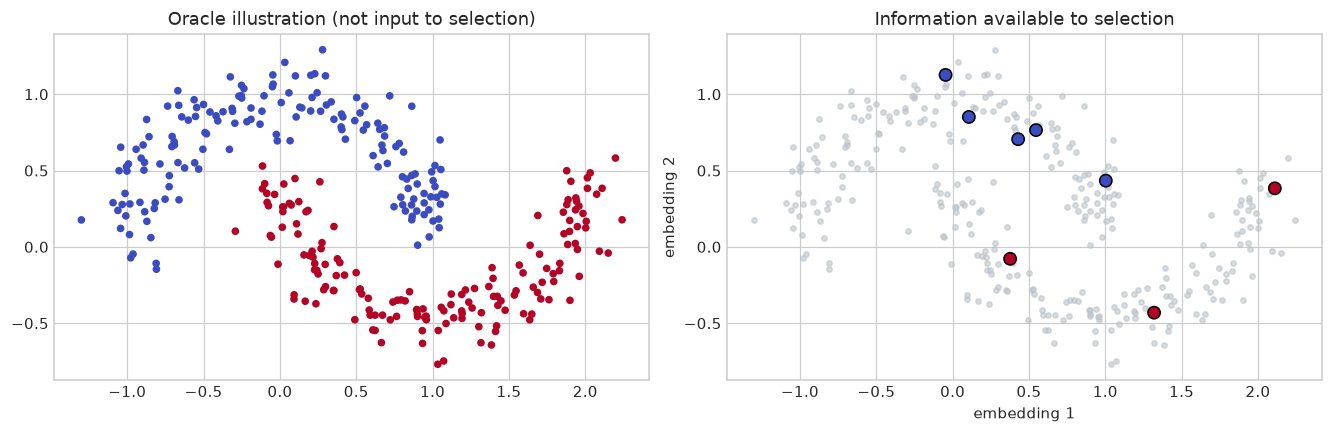

In [4]:
def plot_state(ax, X, labeled, known_y, selected=(), title="", values=None):
    """Unlabeled сірі. Кольори класів використовуємо лише для відомих labels."""
    if values is None:
        ax.scatter(X[:, 0], X[:, 1], s=12, c="#bcc3ca", alpha=0.6)
    else:
        dots = ax.scatter(X[:, 0], X[:, 1], s=20, c=values, cmap="viridis")
        plt.colorbar(dots, ax=ax, fraction=0.035, pad=0.02)
    if len(labeled):
        ax.scatter(X[labeled, 0], X[labeled, 1], c=known_y, cmap="coolwarm",
                   vmin=0, vmax=1, s=65, edgecolors="black", label="Labeled")
    if len(selected):
        ids = np.asarray(selected, dtype=int)
        ax.scatter(X[ids, 0], X[ids, 1], marker="*", c="#f5b700", s=180,
                   edgecolors="black", linewidths=0.7, label="New queries", zorder=5)
    ax.set(title=title, xlabel="embedding 1", ylabel="embedding 2", aspect="equal")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].scatter(X[:, 0], X[:, 1], c=y_oracle, cmap="coolwarm", s=16)
axes[0].set(title="Oracle illustration (not input to selection)", aspect="equal")
plot_state(axes[1], X, L0, y_L0, title="Information available to selection")
plt.show()

## 2. TypiClust: typicality + diversity

Мотивація: на малому бюджеті predictions слабкі. Потрібні представники щільних областей,
але batch з однієї області матиме дублікати.

1. KMeans на всьому `X = L ∪ U`, кількість кластерів `|L| + B`.
2. Пріоритет кластерам із найменшою кількістю вже вибраних labels, потім великим кластерам.
3. У кластері обираємо максимум typicality серед **ще не придбаних ID**.

$$\mathrm{Typ}(x)=\left(\frac1k\sum_{x_j\in kNN(x)}\|x-x_j\|_2+\epsilon\right)^{-1}.$$

В ordinary nondegenerate випадку є щонайменше B кластерів без labels. Якщо через duplicates
кластерів менше, явне правило «найменше labels, потім найбільший розмір» продовжує працювати.

Джерело: [TypiClust, §3.2](https://arxiv.org/html/2202.02794v3#S3.SS2).

In [5]:
def typiclust(X, labeled, budget, k=10, seed=0):
    """Кластеризуємо L ∪ U, у великих непокритих кластерах шукаємо typical points."""
    X = np.asarray(X, dtype=float)
    labeled = np.asarray(labeled, dtype=int)
    U = available_ids(len(X), labeled)
    budget = checked_budget(budget, len(U))
    if k < 1:
        raise ValueError("k має бути додатним")
    if budget == 0:
        return np.array([], dtype=int), {"steps": []}

    # На two moons працюємо без FAISS, GPU та ліміту 500 кластерів.
    n_clusters = min(len(labeled) + budget, len(np.unique(X, axis=0)))
    clusters = KMeans(n_clusters=n_clusters, n_init=10, random_state=seed).fit_predict(X)
    sizes = np.bincount(clusters, minlength=n_clusters)
    counts = np.bincount(clusters[labeled], minlength=n_clusters)
    D = pairwise_distances(X)
    typicality = np.zeros(len(X))

    for cluster in range(n_clusters):
        members = np.flatnonzero(clusters == cluster)
        local_D = D[np.ix_(members, members)].copy()
        np.fill_diagonal(local_D, np.inf)  # сама точка не є своїм сусідом
        n_neighbors = min(k, len(members) - 1)
        if n_neighbors == 0:
            typicality[members] = 0.0  # singleton не оголошуємо нескінченно типовим
        else:
            nearest = np.sort(local_D, axis=1)[:, :n_neighbors]
            typicality[members] = 1 / (nearest.mean(axis=1) + 1e-12)

    selected, steps = [], []
    for _ in range(budget):
        remaining = np.setdiff1d(U, selected)
        candidate_clusters = np.unique(clusters[remaining])
        # Спочатку 0 labels, потім найбільший кластер. ID розв'язує нічию.
        cluster = min(candidate_clusters, key=lambda c: (counts[c], -sizes[c], c))
        candidates = remaining[clusters[remaining] == cluster]
        chosen = candidates[np.argmax(typicality[candidates])]
        steps.append({"chosen": int(chosen), "cluster": int(cluster),
                      "labels_in_cluster_before": int(counts[cluster])})
        selected.append(int(chosen))
        counts[cluster] += 1  # наступна точка має враховувати вже обраний batch

    return np.array(selected), {"steps": steps, "clusters": clusters,
                                "typicality": typicality}


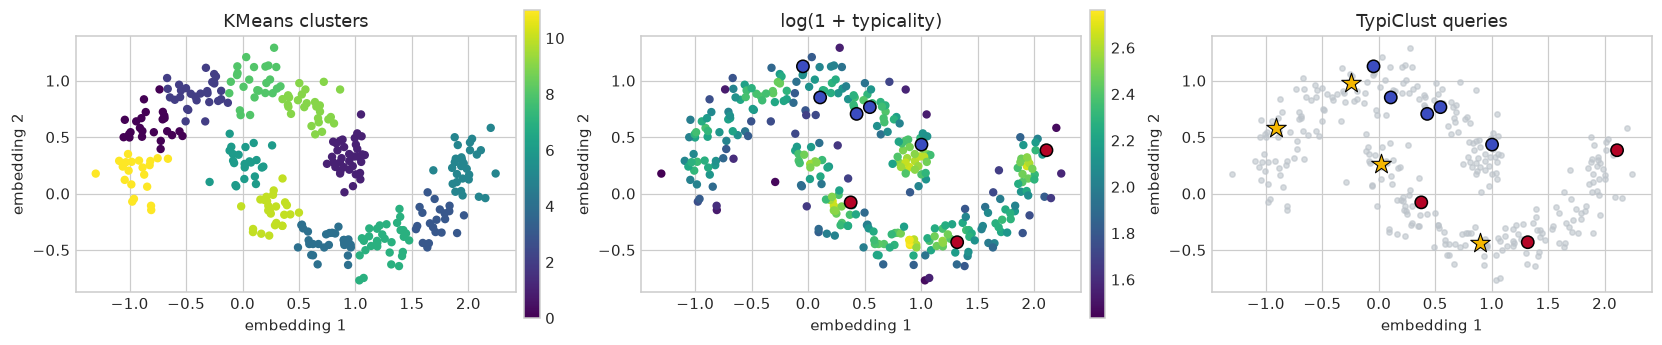

{'chosen': 51, 'cluster': 2, 'labels_in_cluster_before': 0}
{'chosen': 202, 'cluster': 4, 'labels_in_cluster_before': 0}
{'chosen': 67, 'cluster': 0, 'labels_in_cluster_before': 0}
{'chosen': 144, 'cluster': 6, 'labels_in_cluster_before': 0}


In [6]:
typi_ids, typi_info = typiclust(X, L0, BATCH, k=10, seed=SEED)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
plot_state(axes[0], X, [], [], title="KMeans clusters", values=typi_info["clusters"])
plot_state(axes[1], X, L0, y_L0, title="log(1 + typicality)",
           values=np.log1p(typi_info["typicality"]))
plot_state(axes[2], X, L0, y_L0, typi_ids, title="TypiClust queries")
plt.show()
for step in typi_info["steps"]:
    print(step)

## 3. ProbCover: нові покриті точки

$$A_{c,x}=\mathbf1\{\|X_c-X_x\|_2\leq\delta\},\qquad
\mathrm{gain}(c)=|B_\delta(c)\setminus C(L\cup S)|.$$

Тут **row = кандидат c, column = target x**. `A[c, x]` є ребром `c → x`.
Після вибору c прибираємо **всі вхідні ребра до новопокритих targets**:
`remaining_edges[:, newly_covered] = False`.

Ми не видаляємо семпли. Покритий unlabeled кандидат усе ще може покрити інші targets.
L від самого початку визначає вже покриту область. Oracle для цього оновлення не потрібен:
геометрію оновлюємо відразу після додавання кандидата в batch.

Джерело: [ProbCover, Algorithm 1](https://arxiv.org/html/2205.11320v2#alg1).

In [7]:
def probcover(X, labeled, budget, delta=0.22, saturation="stop", seed=0):
    """Жадібне покриття. A[c, x] означає, що кандидат c покриває target x.

    stop: завершити, якщо нове покриття = 0, навіть коли бюджет не вичерпано.
    random: явно добрати залишок випадково; це навчальне доповнення методу.
    """
    if not np.isfinite(delta) or delta <= 0:
        raise ValueError("delta має бути скінченним додатним числом")
    if saturation not in {"stop", "random"}:
        raise ValueError("saturation має бути 'stop' або 'random'")
    labeled = np.asarray(labeled, dtype=int)
    U = available_ids(len(X), labeled)
    budget = checked_budget(budget, len(U))
    rng = np.random.default_rng(seed)
    A = pairwise_distances(X) <= delta  # rows: candidates, columns: targets
    covered = A[labeled].any(axis=0) if len(labeled) else np.zeros(len(X), dtype=bool)
    remaining_edges = A.copy()
    remaining_edges[:, covered] = False  # incoming edges до вже покритих targets
    selected, steps = [], []

    for _ in range(budget):
        candidates = np.setdiff1d(U, selected)
        scores = remaining_edges.sum(axis=1).astype(float)  # out-degree
        scores[np.setdiff1d(np.arange(len(X)), candidates)] = -np.inf
        chosen = int(np.argmax(scores))
        best_gain = int(scores[chosen])
        fallback = best_gain == 0
        if fallback and saturation == "stop":
            break
        if fallback:
            chosen = int(rng.choice(candidates))  # без повторних / labeled ID
        newly_covered = remaining_edges[chosen].copy()
        before = covered.copy()
        covered |= A[chosen]
        remaining_edges[:, newly_covered] = False
        selected.append(chosen)
        steps.append({"chosen": chosen, "gain": int(newly_covered.sum()),
                      "scores": scores.copy(), "covered_before": before,
                      "covered_after": covered.copy(), "fallback": fallback})

    return np.array(selected, dtype=int), {"steps": steps, "adjacency": A,
                                          "covered": covered, "delta": delta,
                                          "saturated": bool(covered.all())}

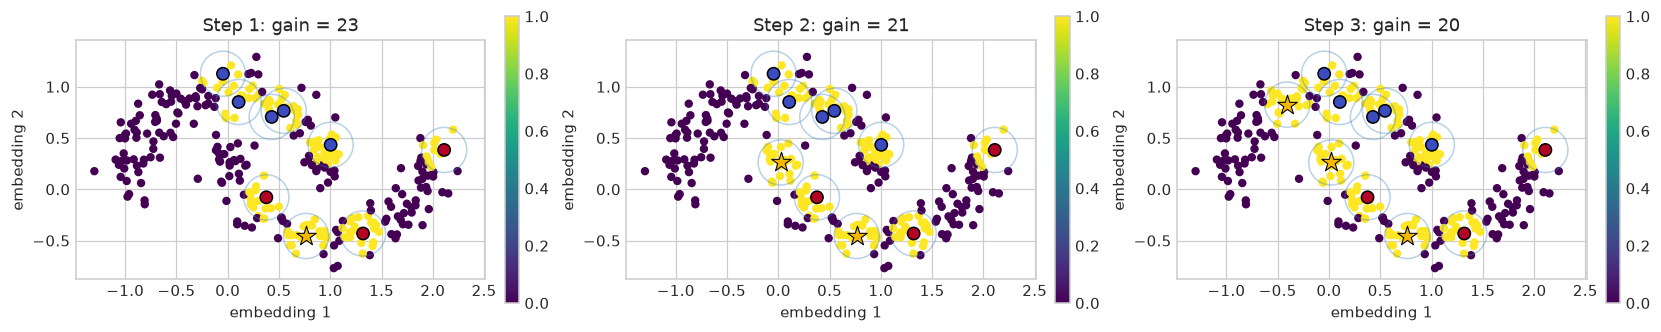

Requested / selected: 4 / 4
Covered fraction: 0.603125


In [8]:
prob_ids, prob_info = probcover(X, L0, BATCH, delta=DELTA)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for j, ax in enumerate(axes):
    step_no = min(j, len(prob_info["steps"]) - 1)
    step = prob_info["steps"][step_no]
    acquired = prob_ids[:step_no + 1]
    plot_state(ax, X, L0, y_L0, acquired,
               title=f"Step {step_no + 1}: gain = {step['gain']}",
               values=step["covered_after"].astype(float))
    for center in np.concatenate([L0, acquired]):
        ax.add_patch(Circle(X[center], DELTA, fill=False, color="#377eb8", alpha=0.35))
plt.show()
print("Requested / selected:", BATCH, "/", len(prob_ids))
print("Covered fraction:", prob_info["covered"].mean())

### Які саме ребра зникають

Для читабельної матриці нижче використовуємо лише 60 точок та порожній L.
Зліва початковий граф, у центрі граф після першого центру. Зникають **цілі стовпці**.
Остання панель показує, як змінюється out-degree кожного кандидата.

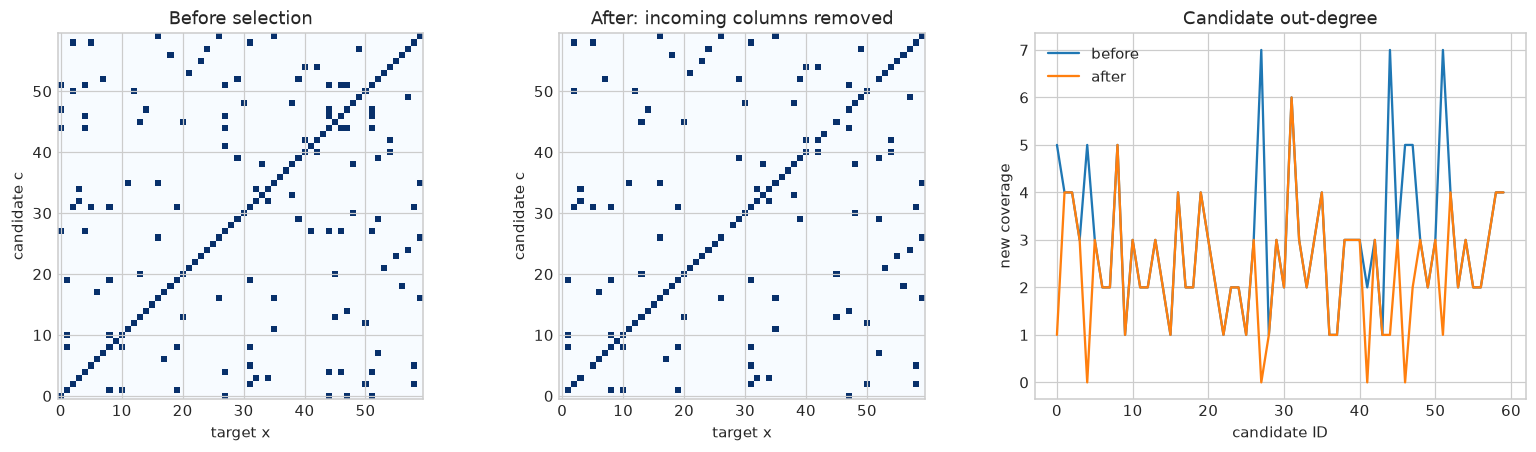

In [9]:
small_X = X[:60]
small_ids, small_info = probcover(small_X, [], 1, delta=DELTA)
A = small_info["adjacency"]
remaining = A.copy()
remaining[:, small_info["covered"]] = False
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
axes[0].imshow(A, cmap="Blues", origin="lower")
axes[0].set(title="Before selection", xlabel="target x", ylabel="candidate c")
axes[1].imshow(remaining, cmap="Blues", origin="lower")
axes[1].set(title="After: incoming columns removed", xlabel="target x", ylabel="candidate c")
axes[2].plot(A.sum(axis=1), label="before")
axes[2].plot(remaining.sum(axis=1), label="after")
axes[2].set(title="Candidate out-degree", xlabel="candidate ID", ylabel="new coverage")
axes[2].legend()
plt.show()

### Повне покриття не означає повне знання міток

За дуже великого δ одна точка може покрити весь пул. Тоді всі marginal gains нульові.
Pure ProbCover не має критерію для наступного порівняння.

За `saturation='stop'` ми зупиняємося. Для learning curves із рівними витратами labels
нижче використовуємо `saturation='random'` і називаємо baseline **ProbCover + random fallback**.
Це не прихована перевага методу. В обох випадках заборонено повторно купувати той самий ID.

In [10]:
stopped, stopped_info = probcover(X, [0], 4, delta=10, saturation="stop")
filled, filled_info = probcover(X, [0], 4, delta=10, saturation="random", seed=SEED)
print("Full coverage:", stopped_info["saturated"])
print("stop queries:", stopped)
print("random fallback queries:", filled)
print("New coverage per query:", [s["gain"] for s in filled_info["steps"]])

Full coverage: True
stop queries: []
random fallback queries: [302 199 218 286]
New coverage per query: [0, 0, 0, 0]


## 4. MaxHerding: плавне покриття

Мотивація: hard threshold δ різко розділяє майже однаково близькі точки.
Замінюємо його Gaussian similarity та зберігаємо **найкраще** покриття кожного target.

$$K_{i,c}=\exp(-\|X_i-X_c\|^2/\sigma^2),\qquad
m_i=\max_{l\in L\cup S}K_{i,l}.$$
$$\Delta(c\mid S)=\frac1{|U_0|}\sum_{i\in U_0}\max(K_{i,c}-m_i,0).$$

`U_0` тут означає unlabeled set **на початку поточного batch**, не всі раунди експерименту.
Вибраний кандидат перестає бути кандидатом, але його target row залишається у цілі.
Rows матриці представляємо, columns обираємо. `coverage = maximum(coverage, K[:, chosen])`.

Джерело: [MaxHerding, §3.2](https://arxiv.org/html/2407.12212v2#S3.SS2).

In [11]:
def greedy_kernel_selection(K, labeled, budget, weights=None):
    """Rows K: точки, які представляємо. Columns K: можливі центри.

    U фіксуємо на ПОЧАТКУ batch. Після вибору target row не прибираємо:
    максимум уже враховує його покриття. Змінюється лише набір кандидатів.
    """
    labeled = np.asarray(labeled, dtype=int)
    U = available_ids(len(K), labeled)
    budget = checked_budget(budget, len(U))
    weights = np.ones(len(K)) if weights is None else np.asarray(weights, dtype=float)
    if weights.shape != (len(K),) or not np.isfinite(weights).all() or np.any(weights < 0):
        raise ValueError("weights: один скінченний невід'ємний scalar на кожну точку X")
    coverage = K[np.ix_(U, labeled)].max(axis=1) if len(labeled) else np.zeros(len(U))
    selected, steps = [], []

    for _ in range(budget):
        candidates = np.setdiff1d(U, selected)
        improvements = np.maximum(K[np.ix_(U, candidates)] - coverage[:, None], 0)
        # weights належать TARGETS (rows), не лише кандидатам (columns)!
        gains = (weights[U, None] * improvements).mean(axis=0)
        chosen = int(candidates[np.argmax(gains)])
        objective_before = float(np.mean(weights[U] * coverage))
        coverage = np.maximum(coverage, K[U, chosen])
        objective_after = float(np.mean(weights[U] * coverage))
        scores = np.full(len(K), np.nan)
        scores[candidates] = gains
        selected.append(chosen)
        steps.append({"chosen": chosen, "gain": float(np.max(gains)),
                      "objective_before": objective_before,
                      "objective_after": objective_after,
                      "scores": scores, "coverage": coverage.copy()})

    return np.array(selected, dtype=int), {"steps": steps, "targets": U,
                                          "coverage": coverage, "weights": weights}


def maxherding(X, labeled, budget, sigma=0.35):
    """MaxHerding = greedy kernel coverage з однаковими вагами targets."""
    K = gaussian_kernel(X, sigma)
    selected, info = greedy_kernel_selection(K, labeled, budget)
    info["sigma"] = sigma
    return selected, info

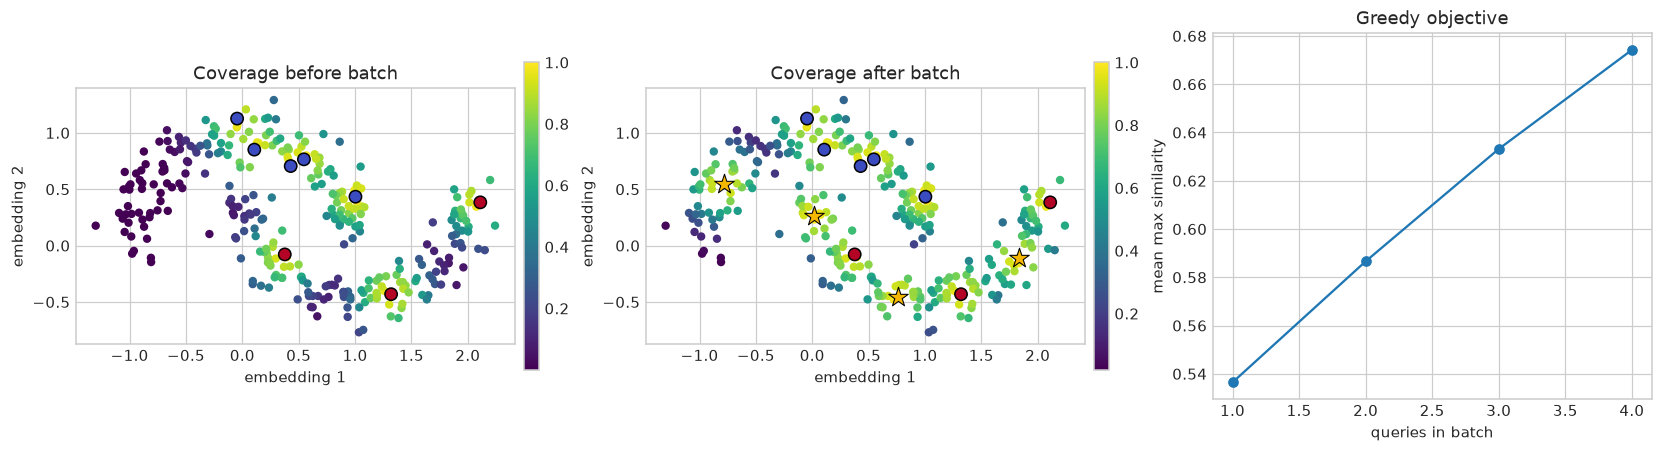

In [12]:
max_ids, max_info = maxherding(X, L0, BATCH, sigma=SIGMA)
K = gaussian_kernel(X, SIGMA)
before = K[:, L0].max(axis=1)
after = K[:, np.concatenate([L0, max_ids])].max(axis=1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
plot_state(axes[0], X, L0, y_L0, title="Coverage before batch", values=before)
plot_state(axes[1], X, L0, y_L0, max_ids, title="Coverage after batch", values=after)
steps = max_info["steps"]
axes[2].plot(np.arange(1, len(steps) + 1), [s["objective_after"] for s in steps], "o-")
axes[2].set(title="Greedy objective", xlabel="queries in batch", ylabel="mean max similarity")
plt.show()

## 5. UHerding: uncertainty зважує targets

Мотивація: не всі непокриті області однаково потрібні навченій моделі.
Зважимо покриття target i його uncertainty. Це **не** `uncertainty[candidate] × density[candidate]`.

$$\Delta_U(c\mid S)=\frac1{|U_0|}\sum_{i\in U_0}U_i\max(K_{i,c}-m_i,0).$$
$$p_\tau(x)=\operatorname{softmax}(z(x)/\tau),\qquad
U_i=1-(p_{(1)}(X_i)-p_{(2)}(X_i)).$$

Спочатку потрібні task learner, температурне масштабування і calibration.
Scores RBF SVC є штучними двокласовими logits `[0, decision_function]`, не готовими probabilities.
Коли відкрито один клас, constant learner дає однакову uncertainty на всьому пулі.

In [13]:
def fit_classifier(X_labeled, y_labeled, seed=0):
    """Нелінійний task learner. Сюди надходять ТІЛЬКИ відкриті мітки."""
    if len(y_labeled) == 0:
        raise ValueError("Для task learner потрібна хоча б одна відкрита мітка")
    if len(np.unique(y_labeled)) == 1:
        model = DummyClassifier(strategy="prior")
    else:
        model = SVC(C=5.0, gamma=2.0, kernel="rbf", random_state=seed)
    return model.fit(X_labeled, y_labeled)


def model_logits(model, X):
    """Двокласові scores [0, decision_function]. SVC score не є probability."""
    logits = np.zeros((len(X), 2))
    if len(model.classes_) == 1:
        # Однокласовий cold start: однакові scores/uncertainty на всьому пулі.
        logits[:, int(model.classes_[0])] = 1.0
    else:
        logits[:, 1] = model.decision_function(X)
    return logits


def softmax(logits, temperature=1.0):
    if not np.isfinite(temperature) or temperature <= 0:
        raise ValueError("temperature має бути додатною")
    scaled = np.asarray(logits) / temperature
    scaled = scaled - scaled.max(axis=1, keepdims=True)
    exp_scores = np.exp(scaled)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)


def margin_uncertainty(probabilities):
    """1 - (p_(1) - p_(2)). Велике значення = висока uncertainty."""
    ordered = np.sort(probabilities, axis=1)
    return np.clip(1 - (ordered[:, -1] - ordered[:, -2]), 0, 1)

### Адаптація параметрів

$$\sigma^*=\min_{u,v\in L,\ u\ne v}\|X_u-X_v\|_2,\qquad
\tau^*=\arg\min_{\tau\in\mathcal T}\mathrm{ECE}(f_{L_{train}},L_{val}).$$

- Train/validation для temperature утворюємо **тільки з придбаних labels**.
- Після цього learner для acquisition перенавчаємо на всьому L. Temperature переносимо з holdout model.
- Для малого L або менш ніж двох прикладів класу використовуємо явний fallback `tau=1`.
- ECE: 5 equal-width bins, невелика сітка temperature. На малому holdout оцінка шумна.
- За менш ніж двох labels σ має fallback 0.35. За duplicates застосовуємо floor 1e-6.
- Sigma й temperature адаптуємо між раундами. Всередині batch вони та uncertainty фіксовані.

Середня accuracy та calibration — різні властивості. Не припускаємо, що τ обов'язково
монотонно зменшується. Мінімальна labeled distance за незмінних features не збільшується.

Джерело: [UHerding, Algorithm 1 і §3.2](https://arxiv.org/html/2412.20644v2#S3.SS2).

In [14]:
def expected_calibration_error(probabilities, labels, n_bins=5):
    """ECE: середня розбіжність confidence та accuracy в equal-width bins."""
    confidence = probabilities.max(axis=1)
    correct = probabilities.argmax(axis=1) == labels
    bin_ids = np.minimum((confidence * n_bins).astype(int), n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        mask = bin_ids == b
        if mask.any():
            ece += mask.mean() * abs(correct[mask].mean() - confidence[mask].mean())
    return float(ece)


def choose_temperature(X_labeled, y_labeled, seed=0,
                       temperatures=(0.25, 0.5, 1, 2, 4, 8)):
    """Paper-style holdout з уже придбаних labels. Test/pool oracle не використовуємо."""
    _, counts = np.unique(y_labeled, return_counts=True)
    if len(y_labeled) < 12 or len(counts) < 2 or counts.min() < 2:
        return 1.0, {"mode": "fallback: недостатньо labeled для holdout", "ece": None}
    train, val = train_test_split(np.arange(len(y_labeled)), test_size=0.3,
                                 stratify=y_labeled, random_state=seed)
    model = fit_classifier(X_labeled[train], y_labeled[train], seed)
    logits = model_logits(model, X_labeled[val])
    errors = [expected_calibration_error(softmax(logits, t), y_labeled[val])
              for t in temperatures]
    best = int(np.argmin(errors))
    return float(temperatures[best]), {"mode": "labeled holdout", "ece": errors,
                                      "temperatures": list(temperatures),
                                      "train_local_ids": train, "val_local_ids": val}


def adaptive_sigma(X, labeled, fallback=0.35, floor=1e-6):
    """Мінімальна відстань між РІЗНИМИ labeled ID. Floor захищає від duplicates."""
    if len(labeled) < 2:
        return fallback
    distances = pairwise_distances(np.asarray(X)[labeled])
    np.fill_diagonal(distances, np.inf)
    return max(float(distances.min()), floor)


def uherding(X, labeled, y_labeled, budget, sigma=None, temperature=None, seed=0):
    """Uncertainty-weighted MaxHerding з адаптацією sigma та temperature.

    y_labeled має відповідати X[labeled] В ТОМУ САМОМУ порядку.
    Ваги та параметри фіксовані протягом batch, learner перенавчаємо між rounds.
    """
    labeled = np.asarray(labeled, dtype=int)
    available_ids(len(X), labeled)
    if len(y_labeled) != len(labeled):
        raise ValueError("Передайте саме y[labeled], а не мітки всього пулу")
    model = fit_classifier(np.asarray(X)[labeled], np.asarray(y_labeled), seed)
    if temperature is None:
        temperature, calibration = choose_temperature(np.asarray(X)[labeled],
                                                      np.asarray(y_labeled), seed)
    else:
        calibration = {"mode": "fixed temperature", "ece": None}
    sigma = adaptive_sigma(X, labeled) if sigma is None else sigma
    probabilities = softmax(model_logits(model, X), temperature)
    weights = margin_uncertainty(probabilities)
    K = gaussian_kernel(X, sigma)
    selected, info = greedy_kernel_selection(K, labeled, budget, weights)
    info.update(sigma=sigma, temperature=temperature, calibration=calibration,
                probabilities=probabilities)
    return selected, info

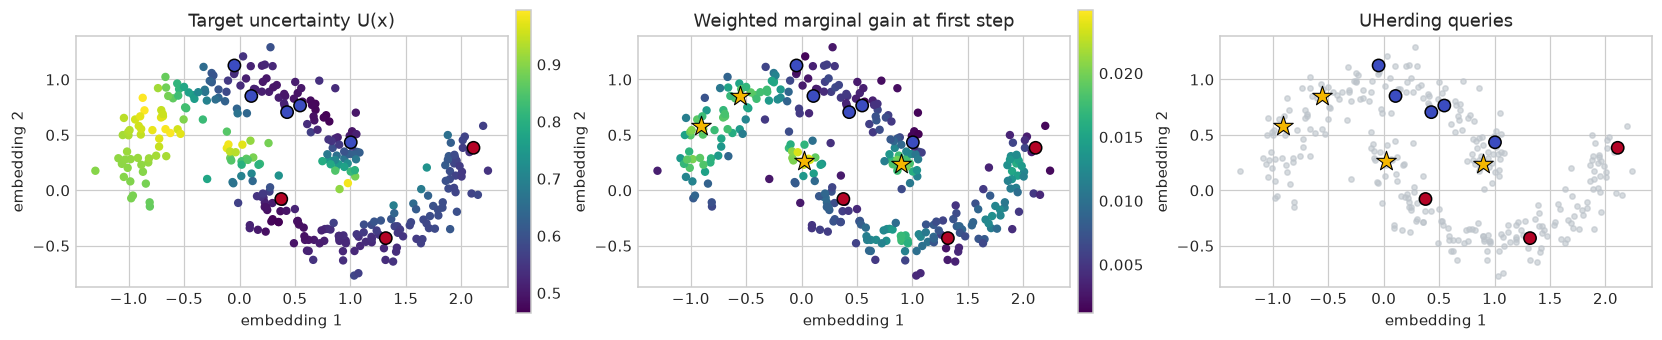

sigma: 0.1315 temperature: 1.0
Calibration: fallback: недостатньо labeled для holdout


In [15]:
u_ids, u_info = uherding(X, L0, y_L0, BATCH, seed=SEED)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
plot_state(axes[0], X, L0, y_L0, title="Target uncertainty U(x)", values=u_info["weights"])
plot_state(axes[1], X, L0, y_L0, u_ids, title="Weighted marginal gain at first step",
           values=u_info["steps"][0]["scores"])
plot_state(axes[2], X, L0, y_L0, u_ids, title="UHerding queries")
plt.show()
print("sigma:", round(u_info["sigma"], 4), "temperature:", u_info["temperature"])
print("Calibration:", u_info["calibration"]["mode"])

## 6. Всі методи на одному старті

Усі методи бачать ті самі embeddings, той самий L та однаковий batch budget.
Золоті зірочки — нові запити, їхні класи ще не показуємо.

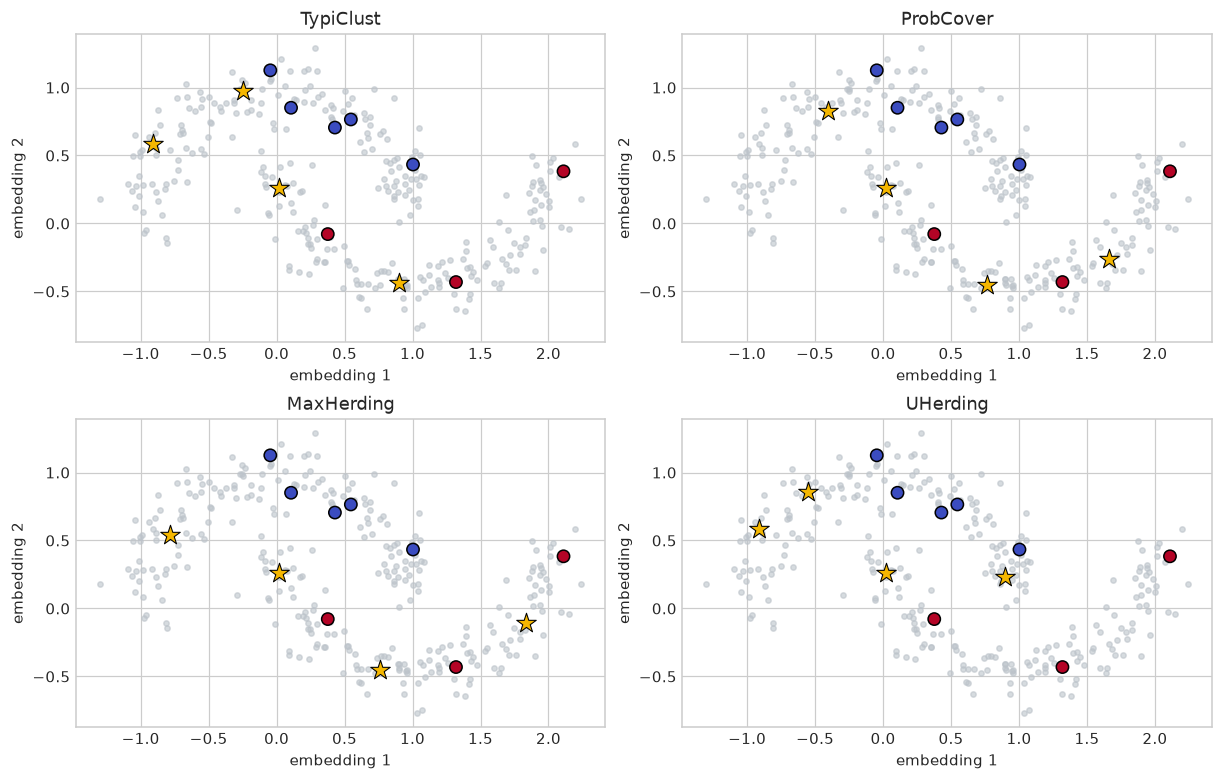

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for ax, name, selected in zip(axes.flat,
        ["TypiClust", "ProbCover", "MaxHerding", "UHerding"],
        [typi_ids, prob_ids, max_ids, u_ids]):
    plot_state(ax, X, L0, y_L0, selected, title=name)
fig.savefig(OUTPUT / "first_batch.png", dpi=160)
plt.show()

## 7. Дві перевірки механізму UHerding

За однакових позитивних ваг UHerding objective збігається з MaxHerding до множника.
За дуже малого σ та відмінних embeddings kernel наближається до identity,
а відбір — до найбільшої uncertainty. Це перевіряє кодову реалізацію, не test accuracy.

In [17]:
K = gaussian_kernel(X, SIGMA)
unweighted, _ = greedy_kernel_selection(K, L0, BATCH)
constant_weights, _ = greedy_kernel_selection(K, L0, BATCH, weights=np.full(len(X), 0.7))
assert np.array_equal(unweighted, constant_weights)
U = available_ids(len(X), L0)
weights = u_info["weights"]
local, _ = greedy_kernel_selection(gaussian_kernel(X, 1e-8), L0, BATCH, weights)
top_uncertainty = U[np.argsort(-weights[U], kind="stable")[:BATCH]]
assert np.array_equal(local, top_uncertainty)
print("Constant uncertainty -> MaxHerding: OK")
print("Tiny sigma -> top uncertainty: OK")

Constant uncertainty -> MaxHerding: OK
Tiny sigma -> top uncertainty: OK


### Чутливість до δ та σ

Це не пошук параметра за test set. Ми показуємо, як зміна локальності змінює сам batch.
Спробуйте NOISE=0.03 і NOISE=0.25, потім виконайте ноутбук з початку.

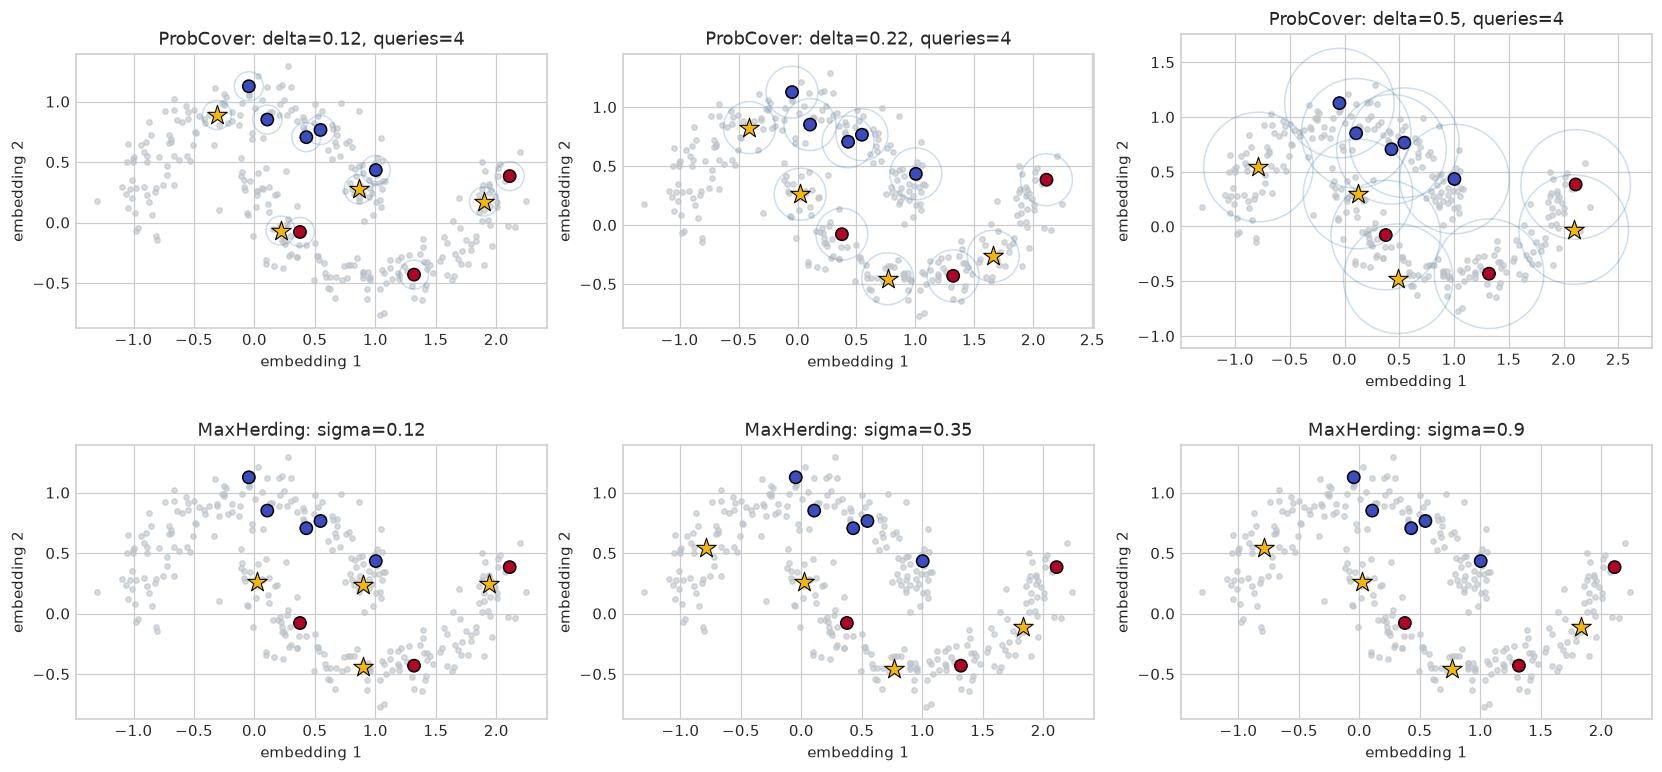

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), constrained_layout=True)
for ax, delta in zip(axes[0], [0.12, 0.22, 0.5]):
    selected, info = probcover(X, L0, BATCH, delta=delta)
    plot_state(ax, X, L0, y_L0, selected, title=f"ProbCover: delta={delta}, queries={len(selected)}")
    for center in np.concatenate([L0, selected]):
        ax.add_patch(Circle(X[center], delta, fill=False, color="#377eb8", alpha=0.25))
for ax, sigma in zip(axes[1], [0.12, 0.35, 0.9]):
    selected, info = maxherding(X, L0, BATCH, sigma=sigma)
    plot_state(ax, X, L0, y_L0, selected, title=f"MaxHerding: sigma={sigma}")
plt.show()

## 8. Повний active learning loop

1. Навчити learner лише на `X[L], y_L`.
2. Вибрати ID S без доступу до прихованих labels.
3. Запитати `y_oracle[S]` та додати їх до y_L у тому самому порядку, що ID у L.
4. Перенавчити learner та оцінити на незалежному test.

Додаткові baselines — random і margin uncertainty. Для UHerding temperature підбираємо
без test set, а task learner для evaluation однаковий у всіх методів.

In [19]:
METHODS = ["Random", "Margin", "TypiClust", "ProbCover + random fallback", "MaxHerding", "UHerding"]

def select_batch(method, X, L, y_L, budget, seed):
    U = available_ids(len(X), L)
    budget = checked_budget(budget, len(U))
    if method == "Random":
        return np.random.default_rng(seed).choice(U, budget, replace=False), {"steps": []}
    if method == "Margin":
        model = fit_classifier(X[L], y_L, seed)
        weights = margin_uncertainty(softmax(model_logits(model, X)))
        return U[np.argsort(-weights[U], kind="stable")[:budget]], {"steps": []}
    if method == "TypiClust":
        return typiclust(X, L, budget, k=10, seed=seed)
    if method == "ProbCover + random fallback":
        return probcover(X, L, budget, delta=DELTA, saturation="random", seed=seed)
    if method == "MaxHerding":
        return maxherding(X, L, budget, sigma=SIGMA)
    if method == "UHerding":
        return uherding(X, L, y_L, budget, seed=seed)
    raise ValueError(method)


def run_active_learning(method, X, oracle, X_test, y_test, initial_ids,
                        rounds=ROUNDS, batch=BATCH, seed=0):
    L = np.asarray(initial_ids, dtype=int).copy()
    y_L = oracle[L].copy()  # початкові labels уже відкрито
    rows = []
    model = fit_classifier(X[L], y_L, seed)
    rows.append(dict(method=method, seed=seed, budget=len(L),
                     accuracy=float(np.mean(model.predict(X_test) == y_test)),
                     sigma=None, temperature=None, random_fallbacks=0))
    for round_id in range(rounds):
        selected, info = select_batch(method, X, L, y_L, batch, seed=seed + round_id)
        assert len(np.unique(selected)) == len(selected)
        assert not np.isin(selected, L).any()
        if len(selected) == 0:
            break
        # Oracle відкриває labels ЛИШЕ ПІСЛЯ вибору.
        new_labels = oracle[selected]
        L = np.concatenate([L, selected])
        y_L = np.concatenate([y_L, new_labels])
        model = fit_classifier(X[L], y_L, seed)
        accuracy = float(np.mean(model.predict(X_test) == y_test))
        fallbacks = sum(s.get("fallback", False) for s in info["steps"])
        rows.append(dict(method=method, seed=seed, budget=len(L), accuracy=accuracy,
                         sigma=info.get("sigma"), temperature=info.get("temperature"),
                         random_fallbacks=int(fallbacks)))
    return rows, L, y_L

### Дизайн експерименту

- 320 pool points і 1600 незалежних test points, `noise=0.12`.
- 8 випадкових labels на старті, потім 10 раундів по 4 labels: фінальний budget 48.
- 5 seeds. Усередині seed pool, test та стартові ID однакові для всіх методів.
- RBF SVC з нуля після кожного batch, фіксовані C=5 та gamma=2.
- Y: test accuracy. Лінія: mean, shading: **standard deviation між seeds**, не SE.
- Для точного порівняння витрат ProbCover добирає нульовий gain випадково.

Криві показують конкретний toy protocol. Перетин curves і розкид важливіші за рейтинг
одного запуску. На простих двох дугах random теж може працювати добре.

In [20]:
SEEDS = list(range(5))
results = []
final_states = {}
for seed in SEEDS:
    X_pool, oracle = make_moons(n_samples=N_POOL, noise=NOISE, random_state=seed)
    X_eval, y_eval = make_moons(n_samples=1600, noise=NOISE, random_state=10000 + seed)
    initial = np.random.default_rng(seed).choice(N_POOL, N_INITIAL, replace=False)
    for method in METHODS:
        rows, final_L, final_y = run_active_learning(
            method, X_pool, oracle, X_eval, y_eval, initial, seed=seed)
        results.extend(rows)
        if seed == SEEDS[0]:
            final_states[method] = (X_pool, final_L, final_y, rows[-1]["accuracy"])
print(f"Finished: {len(SEEDS)} seeds x {len(METHODS)} methods, {len(results)} measurements")

Finished: 5 seeds x 6 methods, 330 measurements


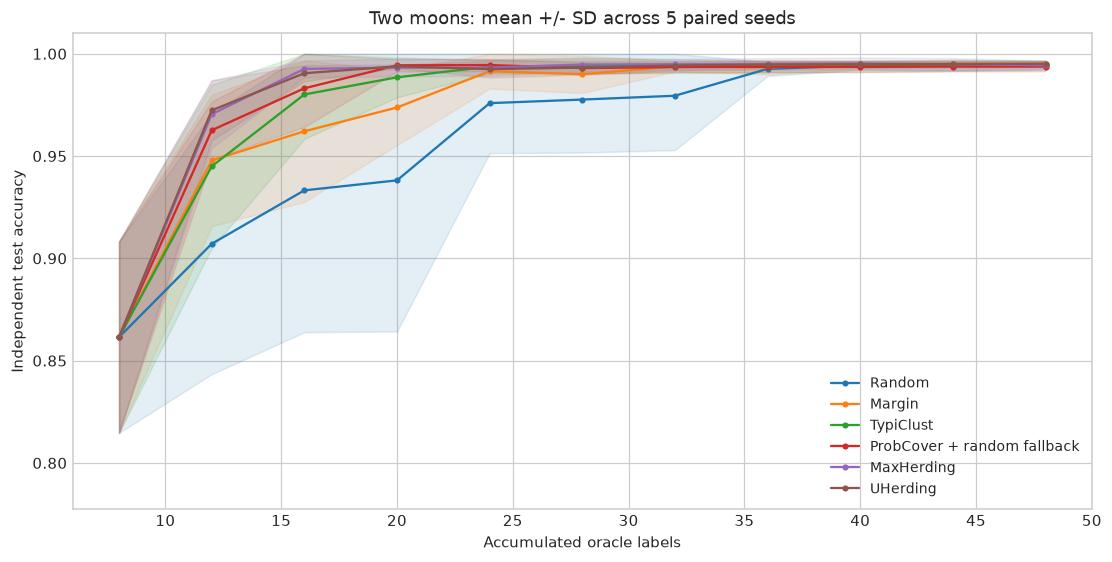

Random                         final accuracy: 0.995 +/- 0.002
Margin                         final accuracy: 0.995 +/- 0.001
TypiClust                      final accuracy: 0.994 +/- 0.002
ProbCover + random fallback    final accuracy: 0.994 +/- 0.002
MaxHerding                     final accuracy: 0.994 +/- 0.002
UHerding                       final accuracy: 0.995 +/- 0.002
Random fallback queries: 43


In [21]:
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
summary = []
for method in METHODS:
    budgets = sorted({r["budget"] for r in results if r["method"] == method})
    scores = np.array([[next(r["accuracy"] for r in results
                            if r["method"] == method and r["seed"] == seed and r["budget"] == budget)
                        for budget in budgets] for seed in SEEDS])
    mean = scores.mean(axis=0)
    sd = scores.std(axis=0, ddof=1)
    line, = ax.plot(budgets, mean, marker="o", markersize=3, label=method)
    ax.fill_between(budgets, np.clip(mean - sd, 0, 1), np.clip(mean + sd, 0, 1),
                    color=line.get_color(), alpha=0.12)
    summary.append((method, mean[-1], sd[-1]))
ax.set(xlabel="Accumulated oracle labels", ylabel="Independent test accuracy",
       title="Two moons: mean +/- SD across 5 paired seeds")
ax.set_ylim(max(0, min(r["accuracy"] for r in results) - 0.03), 1.01)
ax.legend(loc="lower right", fontsize=9)
fig.savefig(OUTPUT / "learning_curves.png", dpi=160)
plt.show()
for method, mean, sd in summary:
    print(f"{method:30s} final accuracy: {mean:.3f} +/- {sd:.3f}")
print("Random fallback queries:", sum(r["random_fallbacks"] for r in results))
with (OUTPUT / "learning_curves.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(results[0]))
    writer.writeheader()
    writer.writerows(results)

### Як змінювалися параметри UHerding

Показуємо один seed, щоб не приховувати стрибки temperature середнім. σ визначається
геометрією накопиченого labeled set, τ — шумним holdout calibration.
Визначення σ гарантує незростання за незмінних features, але не гарантує плавності.

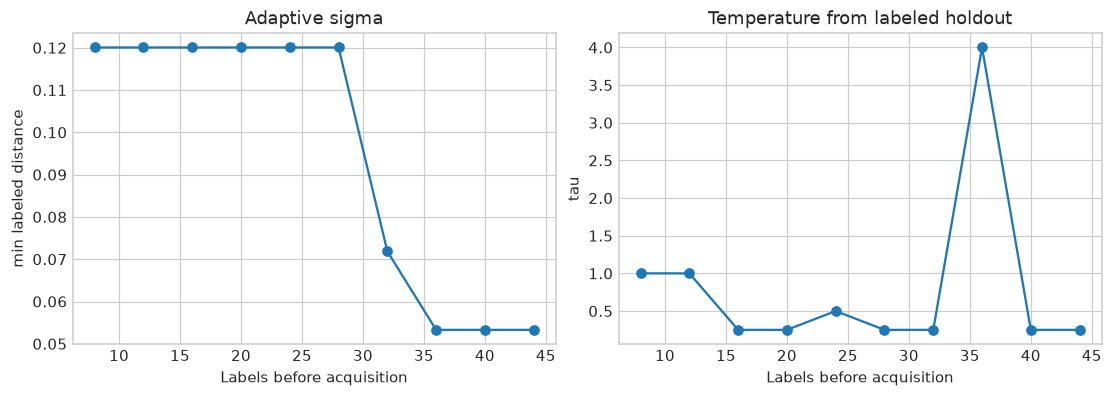

In [22]:
trajectory = [r for r in results if r["method"] == "UHerding" and r["seed"] == 0
              and r["sigma"] is not None]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
axes[0].plot([r["budget"] - BATCH for r in trajectory], [r["sigma"] for r in trajectory], "o-")
axes[0].set(title="Adaptive sigma", xlabel="Labels before acquisition", ylabel="min labeled distance")
axes[1].plot([r["budget"] - BATCH for r in trajectory], [r["temperature"] for r in trajectory], "o-")
axes[1].set(title="Temperature from labeled holdout", xlabel="Labels before acquisition", ylabel="tau")
plt.show()

### Фінальні decision boundaries

Відображаємо один seed та спільний task learner. Кольори точок показують лише придбані labels.
Підкладка — прогноз моделі, тому помилкова область на графіку не є новою міткою oracle.

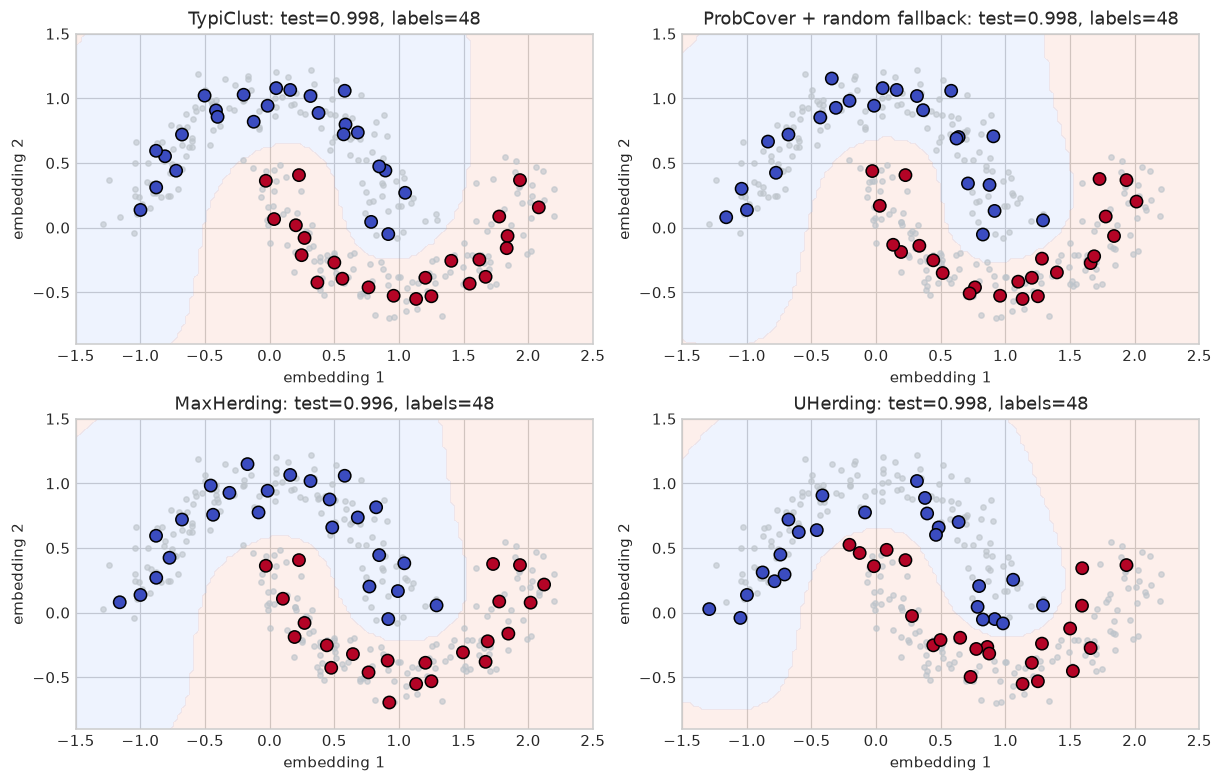

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for ax, method in zip(axes.flat, ["TypiClust", "ProbCover + random fallback", "MaxHerding", "UHerding"]):
    pool, L, known_y, accuracy = final_states[method]
    model = fit_classifier(pool[L], known_y)
    xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 130), np.linspace(-0.9, 1.5, 90))
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    prediction = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, prediction, levels=[-0.5, 0.5, 1.5], cmap="coolwarm", alpha=0.15)
    plot_state(ax, pool, L, known_y, title=f"{method}: test={accuracy:.3f}, labels={len(L)}")
fig.savefig(OUTPUT / "final_boundaries.png", dpi=160)
plt.show()

## 9. Вправи для лекції

3. Передайте UHerding однакові weights. Перевірте збіг з MaxHerding за однакового σ.
8. Приберіть частину стартових labels. Поясніть, чому той самий кандидат тепер може мати інший gain.

### Межі цієї демонстрації

Щільні матриці потребують O(N²) пам'яті. Це свідомий вибір для кількох сотень точок.
Немає image encoder training, пошуку оптимального δ, великого benchmark або гарантії,
що один метод переможе на всіх seeds. Мета — зрозуміти objective та його оновлення.

### Першоджерела

- [TypiClust, ICML 2022, §3.2](https://arxiv.org/abs/2202.02794)
- [ProbCover, NeurIPS 2022, Algorithm 1](https://arxiv.org/abs/2205.11320)
- [MaxHerding, ECCV 2024, §3.2](https://arxiv.org/abs/2407.12212)
- [UHerding, ICLR 2025, Algorithm 1 та parameter adaptation](https://arxiv.org/abs/2412.20644)
- [Офіційний код TypiClust / ProbCover](https://github.com/avihu111/TypiClust)

Код notebook написаний для цієї лекції, а не скопійований із production implementations.